<!-- TEACHER VERSION - fully worked, with teaching notes -->
# Can a computer spot a fake planet?

### A two-week machine-learning project on Kepler transit light curves

**The question you are answering**

> What fraction of Kepler's false positives can be identified from the shape of the
> light curve alone?

About half of the signals that look like a planet transit are not planets. Most are
**eclipsing binaries**: two stars orbiting each other and passing in front of one another.
Sometimes it is the star you are looking at, and sometimes it is a fainter pair of stars
nearby whose light lands on the same camera pixels.

You will measure ten numbers from each light curve, train a Random Forest to tell planets
from false positives using only those ten numbers, and then work out which false positives
cannot be found this way, and why.

**How the notebook is organised**

| | | |
|---|---|---|
| **Week 1** | Part 1 &middot; Stage A | The catalogue, and the clue hidden in it |
| | Part 2 &middot; Stage B | From brightness to numbers |
| **Week 2** | Part 3 &middot; Stage C | Training the model |
| | Part 4 &middot; Stage D | Finding the limit |

All the code is written for **Python 3.9 or later**. Functions use type hints and file
paths use `pathlib.Path`. Results are shown with plain `print()` commands, in which each
item is separated by a comma and Python puts a space between them.

**Before you start** you should be comfortable downloading a light curve with
`lightkurve`, removing instrument trends, and folding on a period. Those are covered in
the earlier notes for this project.

---
> ### Teacher note
>
> The project is built so that the final answer is a **limit**, not a score. Even a group
> whose model performs poorly reaches a defensible conclusion in Part 4, because the result
> is about which errors are unavoidable rather than about how few errors there are.
> 
> Protect one idea above all others: a very high score is a reason to look for a mistake.
> Part 1 is designed to produce a suspiciously good result deliberately, so that students
> discover data leakage instead of being warned about it.
> 
> Suggested timing: Part 1 in session 1, the first half of Part 2 in session 2, the download
> loop as homework, the rest of Part 2 plus Part 3 in session 3, and Part 4 in session 4.

## Part 0 &mdash; Setting up

Run the next two cells once at the start of every session.

**New things in the next cell**

| Name | What it is | What it does |
|---|---|---|
| `!pip install` | notebook command | The `!` runs a terminal command from inside a notebook. On your own computer you can run the same line in a terminal without the `!`. |
| `-q` | option | Short for quiet. It hides the long list of installation messages. |

In [ ]:
# Install the five libraries this project needs.
# On Google Colab this must be run once each time you open the notebook.
!pip install lightkurve scikit-learn pandas matplotlib numpy -q

**New things in the next cell**

| Name | What it is | What it does |
|---|---|---|
| `np` | library (numpy) | Fast arrays of numbers, and the mathematics that goes with them. |
| `pd` | library (pandas) | Tables of data, like a spreadsheet you control with code. |
| `plt` | library (matplotlib) | Everything to do with making plots. |
| `lk` | library (lightkurve) | Downloads and handles Kepler and TESS light curves. |
| `Path` | class (pathlib) | The modern Python 3 way to describe a folder or file location. |
| `warnings.filterwarnings` | function | Hides warning messages. lightkurve produces many harmless ones that would otherwise fill the screen. |
| `plt.rcParams` | settings dictionary | Default settings for every plot, so you do not have to repeat them. |
| `DATA_DIR` | variable (Path) | The folder where every file this notebook creates is saved. |
| `RANDOM_STATE` | variable (int) | A fixed number that makes every random choice repeatable. Using the same value means you get the same answer if you run the notebook again. |
| `print(a, b, c)` | built-in function | Displays several items on one line. Separate them with commas and Python puts a single space between each one. |
| `round(value, n)` | built-in function | Rounds a number to n decimal places, so long decimals do not clutter the output. With no n it rounds to a whole number. |

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightkurve as lk

warnings.filterwarnings("ignore")     # lightkurve prints many harmless notices

plt.rcParams["figure.figsize"] = (9, 4)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.25

DATA_DIR = Path("koi_project")        # every file we create goes in here
DATA_DIR.mkdir(exist_ok=True)         # make the folder if it does not exist yet

RANDOM_STATE = 42                     # fixing this makes your results repeatable

print("lightkurve version", lk.__version__)
print("saving everything into:", DATA_DIR.resolve())

lightkurve version 2.6.0
saving everything into: D:\Anaconda projects\Exoplanet detection through transits\C. ML Tutorial\Trial 2\koi_project


D:\Anaconda\Lib\site-packages\lightkurve\prf\__init__.py:7: UserWarning: Warning: the tpfmodel submodule is not available without oktopus installed, which requires a current version of autograd. See #1452 for details.
  warnings.warn(


---
# PART 1 &mdash; Stage A: The catalogue, and the clue hidden in it

You will not open a single light curve in this Part. Instead you build a classifier using
only the numbers already listed in the catalogue, get a very high score, and then find out
why that score was not real.

## 1.1 Download the KOI catalogue

The NASA Exoplanet Archive stores a **table** of Kepler Objects of Interest. Each row is
one candidate signal, with its period, depth, duration and the verdict astronomers reached.
The table does not contain the light curves themselves. Those live at a different archive
called MAST, and you will download them in Part 2.

We keep only the two verdicts we can rely on:

- `CONFIRMED` &mdash; follow-up observations proved it is a planet
- `FALSE POSITIVE` &mdash; follow-up observations proved it is not

We drop rows marked `CANDIDATE`, because "not decided yet" is not something a model can
learn from.

**New things in the next cell**

| Name | What it is | What it does |
|---|---|---|
| `BASE` | variable (str) | The web address of the archive's query service. |
| `COLUMNS` | variable (list of str) | The names of the catalogue columns we want. |
| `adql` | variable (str) | The database query itself. ADQL is a language very close to SQL, used by astronomy archives. |
| `urllib.parse.quote` | function | Converts spaces and symbols in the query into a form that is safe to put inside a web address. |
| `pd.read_csv` | function | Reads a comma-separated table into a pandas DataFrame. It can read from a web address as well as from a file. |
| `koi` | variable (DataFrame) | The whole catalogue as a table you can filter and plot. |
| `is_fp` | new column (int) | Our label: 1 if the object is a false positive, 0 if it is a confirmed planet. |
| `.astype(int)` | method | Converts True and False into 1 and 0. |
| `.nunique()` | method | Counts how many different values a column contains. |
| `.value_counts()` | method | Counts how many rows fall into each category. |

In [2]:
import urllib.parse

BASE = "https://exoplanetarchive.ipac.caltech.edu/TAP/sync"

COLUMNS = [
    # identification
    "kepid", "kepoi_name", "kepler_name", "koi_disposition",
    # the ephemeris, needed later to fold the light curve
    "koi_period", "koi_time0bk", "koi_duration", "koi_depth",
    # physical quantities measured by the Kepler pipeline
    "koi_model_snr", "koi_prad", "koi_impact", "koi_srad", "koi_steff",
    # the pipeline's own verdict and its reasons - we must NOT train on these
    "koi_score", "koi_fpflag_nt", "koi_fpflag_ss", "koi_fpflag_co", "koi_fpflag_ec",
]

column_list = ",".join(COLUMNS)          # join the column names with commas
adql = ("select " + column_list + " from cumulative "
        "where koi_disposition in ('CONFIRMED','FALSE POSITIVE')")
url = BASE + "?query=" + urllib.parse.quote(adql) + "&format=csv"

koi = pd.read_csv(url)
koi["is_fp"] = (koi["koi_disposition"] == "FALSE POSITIVE").astype(int)
koi.to_csv(DATA_DIR / "koi_cumulative.csv", index=False)

print(len(koi), "rows, covering", koi["kepid"].nunique(), "different stars")
print(koi["koi_disposition"].value_counts())
koi.head()

7587 rows, covering 6641 different stars
koi_disposition
FALSE POSITIVE    4839
CONFIRMED         2748
Name: count, dtype: int64


,kepid,kepoi_name,kepler_name,koi_disposition,koi_period,koi_time0bk,koi_duration,koi_depth,koi_model_snr,koi_prad,koi_impact,koi_srad,koi_steff,koi_score,koi_fpflag_nt,koi_fpflag_ss,koi_fpflag_co,koi_fpflag_ec,is_fp
0,10797460,K00752.01,Kepler-227 b,CONFIRMED,9.488036,170.538750,2.95750,615.8,35.8,2.26,0.146,0.927,5455.0,1.000,0,0,0,0,0
1,10797460,K00752.02,Kepler-227 c,CONFIRMED,54.418383,162.513840,4.50700,874.8,25.8,2.83,0.586,0.927,5455.0,0.969,0,0,0,0,0
2,10848459,K00754.01,NaN,FALSE POSITIVE,1.736952,170.307565,2.40641,8079.2,505.6,33.46,1.276,0.791,5805.0,0.000,0,1,0,0,1
3,10854555,K00755.01,Kepler-664 b,CONFIRMED,2.525592,171.595550,1.65450,603.3,40.9,2.75,0.701,1.046,6031.0,1.000,0,0,0,0,0
4,10872983,K00756.01,Kepler-228 d,CONFIRMED,11.094321,171.201160,4.59450,1517.5,66.5,3.90,0.538,0.972,6046.0,1.000,0,0,0,0,0


Notice that there are more rows than stars. Some stars have more than one candidate signal
(`K00001.01`, `K00001.02`, and so on). Remember this, because it matters in Part 3.

## 1.2 Look at the data before building any model

Always plot your data before you model it. You are checking two things: how much the two
groups overlap, and how many objects are in each group.

**New things in the next cell**

| Name | What it is | What it does |
|---|---|---|
| `plt.subplots` | function | Creates a figure and a set of axes to draw on. Here it makes one row of three plots. |
| `axes` | variable (array) | The three sets of axes, used as `axes[0]`, `axes[1]`, `axes[2]`. |
| `np.log10` | function | Base-10 logarithm. Depths range from tens to hundreds of thousands of ppm, so a log scale makes the histogram readable. |
| `.dropna()` | method | Removes missing values, which would otherwise break the histogram. |
| `.clip(0, 1.5)` | method | Limits values to a range, so a few extreme points do not stretch the axis. |
| `.groupby("is_fp")` | method | Splits the table into the two groups so each can be drawn in a different colour. |
| `ax.hist` | method | Draws a histogram: how many objects fall in each bin of values. |
| `plt.tight_layout()` | function | Adjusts the spacing so labels do not overlap. |

fraction of objects that are false positives: 0.638


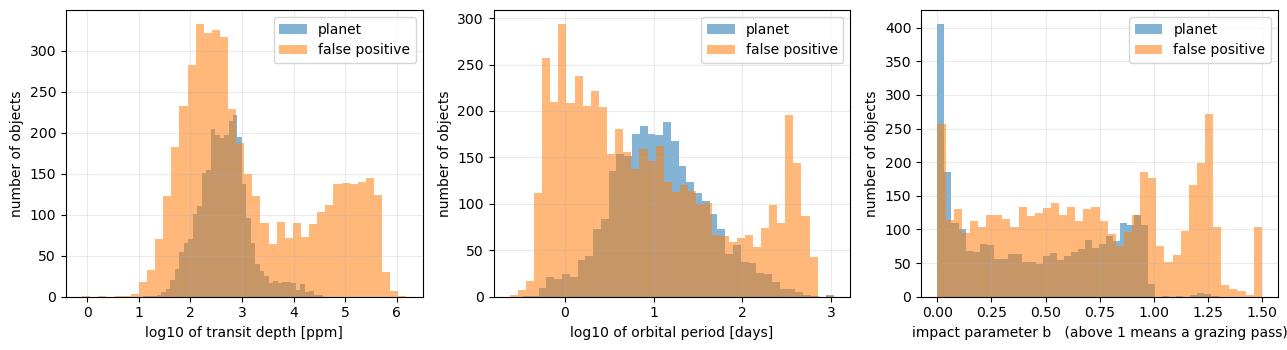

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))

for label, subset in koi.groupby("is_fp"):
    name = "false positive" if label == 1 else "planet"
    axes[0].hist(np.log10(subset["koi_depth"].dropna()), bins=40, alpha=0.55, label=name)
    axes[1].hist(np.log10(subset["koi_period"].dropna()), bins=40, alpha=0.55, label=name)
    axes[2].hist(subset["koi_impact"].dropna().clip(0, 1.5), bins=40, alpha=0.55, label=name)

axes[0].set_xlabel("log10 of transit depth [ppm]")
axes[1].set_xlabel("log10 of orbital period [days]")
axes[2].set_xlabel("impact parameter b   (above 1 means a grazing pass)")
for ax in axes:
    ax.set_ylabel("number of objects")
    ax.legend()
plt.tight_layout()

baseline_guess = koi["is_fp"].mean()
print("fraction of objects that are false positives:", round(baseline_guess, 3))

That last number is the **guessing baseline** and every later score must be compared
against it.

---
> ### Teacher note
>
> Ask the class directly: "if I write a program that always answers *false positive*, what
> accuracy do I get?" Let them work out that it is about 0.47 before you tell them. This
> makes the switch to precision and recall feel necessary rather than arbitrary.
> 
> The impact-parameter histogram is worth pausing on. Values above 1 mean the smaller body
> only clips the edge of the star, which is where grazing eclipsing binaries live. Students
> who notice this on their own are ready for the `v_shape` feature in Part 2.

## 1.3 The leakage check

**Data leakage** means a column secretly contains the answer. A model that uses such a
column will score very highly without having learned anything useful.

Go through the columns and remove every one that a person filled in *after* deciding
whether the object was a planet:

| Column | Why it has to go |
|---|---|
| `koi_disposition` | It is the answer itself. |
| `koi_score` | The pipeline's own confidence in the answer. |
| `koi_fpflag_nt`, `_ss`, `_co`, `_ec` | The four reasons an object was rejected. |
| `kepler_name` | Only confirmed planets are ever given a name, so an empty name is the answer. |
| `kepid`, `kepoi_name` | Identification numbers. A model can memorise them. |

Everything else is a measurement of the star or the signal, so it is allowed.

**New things in the next cell**

| Name | What it is | What it does |
|---|---|---|
| `BANNED` | variable (list of str) | Every column that must never be used for training. |
| `CATALOG_FEATURES` | variable (list of str) | The eight measurement columns we are allowed to train on in this Part. |
| `set(...)` | built-in type | A collection with no duplicates. Two sets can be compared quickly. |
| `&` | operator on sets | Intersection: the items that appear in both sets. Here it should be empty. |
| `assert` | statement | Stops the notebook with an error if the condition is not true. Use it to catch your own mistakes early. |

In [4]:
BANNED = [
    "koi_disposition", "koi_score", "kepler_name", "kepoi_name", "kepid",
    "koi_fpflag_nt", "koi_fpflag_ss", "koi_fpflag_co", "koi_fpflag_ec", "is_fp",
]

CATALOG_FEATURES = [
    "koi_period", "koi_duration", "koi_depth", "koi_model_snr",
    "koi_prad", "koi_impact", "koi_srad", "koi_steff",
]

overlap = set(CATALOG_FEATURES) & set(BANNED)
assert not overlap, "a banned column got into the feature list"

print("training on", len(CATALOG_FEATURES), "columns:")
print(CATALOG_FEATURES)

training on 8 columns:
['koi_period', 'koi_duration', 'koi_depth', 'koi_model_snr', 'koi_prad', 'koi_impact', 'koi_srad', 'koi_steff']


## 1.4 A first model, and why we split the data by star

Some stars have several candidate signals. If `K00001.01` is used for training and
`K00001.02` is used for testing, then the model is being tested on something very similar
to what it has already seen, and the score comes out too high. This is another form of
leakage.

`GroupShuffleSplit` fixes this by keeping every row belonging to one `kepid` on the same
side of the split.

**New things in the next cell**

| Name | What it is | What it does |
|---|---|---|
| `RandomForestClassifier` | class (scikit-learn) | The model itself: many decision trees that each vote on the answer. |
| `n_estimators=400` | setting | How many trees are in the forest. More trees is steadier but slower. |
| `min_samples_leaf=3` | setting | A tree is not allowed to make a decision based on fewer than three objects. This stops it memorising individual stars. |
| `class_weight="balanced"` | setting | Treats the smaller class as equally important, so the model cannot succeed by ignoring it. |
| `n_jobs=-1` | setting | Use all the processor cores available. |
| `GroupShuffleSplit` | class (scikit-learn) | Splits data into training and test sets while keeping each group entirely on one side. |
| `groups` | variable (Series) | The `kepid` of every row. This is what the split is grouped on. |
| `train_idx, test_idx` | variables (arrays) | The row positions belonging to each side of the split. |
| `.iloc[...]` | method | Selects rows by position number rather than by label. |
| `classification_report` | function | Prints precision, recall and f1-score for each class. |
| `confusion_matrix` | function | A 2x2 table of how many objects of each true class were given each predicted class. |

In [5]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import classification_report, confusion_matrix

clean = koi.dropna(subset=CATALOG_FEATURES + ["is_fp"])
X = clean[CATALOG_FEATURES]
y = clean["is_fp"]
groups = clean["kepid"]

splitter = GroupShuffleSplit(n_splits=1, test_size=0.30, random_state=RANDOM_STATE)
train_idx, test_idx = next(splitter.split(X, y, groups=groups))

# check that no star ended up on both sides
shared = set(groups.iloc[train_idx]) & set(groups.iloc[test_idx])
assert not shared, "some stars appear in both the training and test sets"

forest = RandomForestClassifier(
    n_estimators=400,
    min_samples_leaf=3,
    class_weight="balanced",
    random_state=RANDOM_STATE,
    n_jobs=-1,
)
forest.fit(X.iloc[train_idx], y.iloc[train_idx])
predictions = forest.predict(X.iloc[test_idx])

print(classification_report(y.iloc[test_idx], predictions,
                            target_names=["planet", "false positive"], digits=3))
print("confusion matrix (rows = truth, columns = prediction)")
print(confusion_matrix(y.iloc[test_idx], predictions))

                precision    recall  f1-score   support

        planet      0.881     0.914     0.897       775
false positive      0.951     0.932     0.941      1404

      accuracy                          0.925      2179
     macro avg      0.916     0.923     0.919      2179
  weighted avg      0.926     0.925     0.925      2179

confusion matrix (rows = truth, columns = prediction)
[[ 708   67]
 [  96 1308]]


---
> ### Teacher note
>
> Typical recall here is high, because these catalogue columns were fitted by the Kepler
> pipeline using the full mission dataset. Students should not expect to beat it in Part 3
> with ten hand-measured features from a hundred objects, and they should not feel that
> failing to beat it is a failure. Explaining the gap is worth more than closing it.
> 
> If a group asks why we bother with Part 2 at all, the answer is in the next cell: the
> catalogue numbers were produced by the same pipeline that decided the verdict, so a good
> score here does not prove the light curve itself carries the information.

## 1.5 Now break the model deliberately

Put `koi_score` back into the feature list and run the same model again. Watch what happens
to the accuracy and to the list of important features.

**New things in the next cell**

| Name | What it is | What it does |
|---|---|---|
| `leaky_features` | variable (list of str) | The allowed columns plus the banned `koi_score`, used here to demonstrate the problem. |
| `.score(...)` | method | Returns the accuracy: the fraction of test objects predicted correctly. |
| `.feature_importances_` | attribute | How much each feature contributed to the forest's decisions. The values add up to 1. |
| `pd.Series` | class | A single labelled column of values. Used here to attach feature names to the importance numbers so they can be sorted and printed. |

In [6]:
leaky_features = CATALOG_FEATURES + ["koi_score"]

clean_leaky = koi.dropna(subset=leaky_features + ["is_fp"])
X_leaky = clean_leaky[leaky_features]
y_leaky = clean_leaky["is_fp"]
groups_leaky = clean_leaky["kepid"]

leaky_splitter = GroupShuffleSplit(n_splits=1, test_size=0.30, random_state=RANDOM_STATE)
train_leaky, test_leaky = next(leaky_splitter.split(X_leaky, y_leaky, groups=groups_leaky))

forest_leaky = RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1)
forest_leaky.fit(X_leaky.iloc[train_leaky], y_leaky.iloc[train_leaky])

accuracy = forest_leaky.score(X_leaky.iloc[test_leaky], y_leaky.iloc[test_leaky])
print("accuracy with koi_score included:", round(accuracy, 4))

importances = pd.Series(forest_leaky.feature_importances_, index=leaky_features)
print()
print("feature importances, largest first:")
print(importances.sort_values(ascending=False).round(3).to_string())

accuracy with koi_score included: 0.977

feature importances, largest first:
koi_score        0.643
koi_prad         0.131
koi_period       0.065
koi_depth        0.046
koi_impact       0.042
koi_model_snr    0.035
koi_duration     0.015
koi_steff        0.014
koi_srad         0.009


---
> ### Teacher note
>
> This is the moment the project turns on. Do not rush it. Ask students to say out loud what
> the model has actually learned, and keep asking until someone says "it just copied the
> answer".
> 
> A good follow-up question: `kepler_name` is not a number at all, so how could it leak?
> Answer: only confirmed planets have one, so *whether the field is empty* is the label.
> Any model that turns text into a number, including simply asking "is this missing?", will
> find it.

---
# PART 2 &mdash; Stage B: From brightness to numbers

This is the longest Part. You will download about a hundred light curves, clean them, and
turn each one into ten numbers that you measured yourself.

## 2.1 Choose a balanced sample

Downloading all nine thousand KOIs would take days. Take fifty of each class instead.
Choosing equal numbers also stops the model from succeeding by simply guessing whichever
class is more common.

**New things in the next cell**

| Name | What it is | What it does |
|---|---|---|
| `N_PER_CLASS` | variable (int) | How many objects of each class to download. Start small and increase it once everything works. |
| `.dropna(subset=[...])` | method | Removes rows where any of the listed columns is missing. We need period, epoch and duration to fold the light curve. |
| `.groupby("is_fp").sample(...)` | method chain | Takes the same number of random rows from each group. Available in pandas 1.1 and later. |
| `random_state=RANDOM_STATE` | setting | Makes the random choice repeatable, so you can come back tomorrow and get the same fifty objects. |
| `.reset_index(drop=True)` | method | Renumbers the rows from 0 after the sampling, and throws away the old numbering. |
| `sample` | variable (DataFrame) | The hundred objects you will actually measure. |

In [7]:
N_PER_CLASS = 50        # increase this later if you have time and bandwidth

usable = koi.dropna(subset=["koi_period", "koi_time0bk", "koi_duration"])

sample = (
    usable.groupby("is_fp")
          .sample(n=N_PER_CLASS, random_state=RANDOM_STATE)
          .reset_index(drop=True)
)
sample.to_csv(DATA_DIR / "sample.csv", index=False)

print(sample["is_fp"].value_counts())
sample[["kepoi_name", "kepid", "koi_disposition",
        "koi_period", "koi_duration", "koi_depth"]].head()

is_fp
0    50
1    50
Name: count, dtype: int64


,kepoi_name,kepid,koi_disposition,koi_period,koi_duration,koi_depth
0,K03384.02,8644365,CONFIRMED,19.915886,6.1910,143.2
1,K01804.01,11187436,CONFIRMED,5.907415,1.0160,5569.0
2,K02494.01,7047207,CONFIRMED,19.118742,6.8050,217.5
3,K00369.01,7175184,CONFIRMED,5.885274,1.9531,112.7
4,K04014.01,9009953,CONFIRMED,234.240739,12.9250,464.1


## 2.2 Download and clean one light curve

Three details here matter a great deal, and each one is a place where things go wrong.

1. **`author="Kepler"`** asks for the official mission product. Without it you may get
   several different community versions of the same star mixed together.
2. **`remove_outliers(sigma_upper=4, sigma_lower=20)`** removes points that are unusually
   *bright*, such as cosmic ray hits and flares, but leaves faint points alone. The usual
   symmetric setting would delete deep eclipses, which are exactly the signals you want to
   keep.
3. **`flatten(mask=...)`** fits a smooth curve to the star's slow brightness changes and
   divides it out. The mask tells it to ignore the in-transit points while fitting.
   Without the mask, the smooth curve bends down into your transit and removes it.

**New things in the next cell**

| Name | What it is | What it does |
|---|---|---|
| `def name(...) -> type:` | Python 3 syntax | The arrow shows what type of value the function returns. It is a note for the reader; Python does not enforce it. |
| `lk.search_lightcurve` | function | Searches the MAST archive for light curves of one star. |
| `author="Kepler"` | argument | Restricts the search to the official mission data. |
| `cadence="long"` | argument | The 30-minute sampling, which is what most Kepler targets have. |
| `.download_all()` | method | Downloads every matching file and returns a collection. |
| `.stitch()` | method | Joins the separate quarters into one series and scales the brightness so the typical value is 1. |
| `.remove_nans()` | method | Drops time steps where the brightness is missing. |
| `.remove_outliers(...)` | method | Removes points far from the typical brightness. The two sigma settings control how far, upwards and downwards separately. |
| `.create_transit_mask(...)` | method | Returns True at every time step that falls inside a transit. |
| `.flatten(window_length=401, mask=...)` | method | Divides out slow trends. The window is measured in data points, and 401 points is about eight days. |
| `Optional[lk.LightCurve]` | type hint | Means the function returns either a light curve or `None`. |

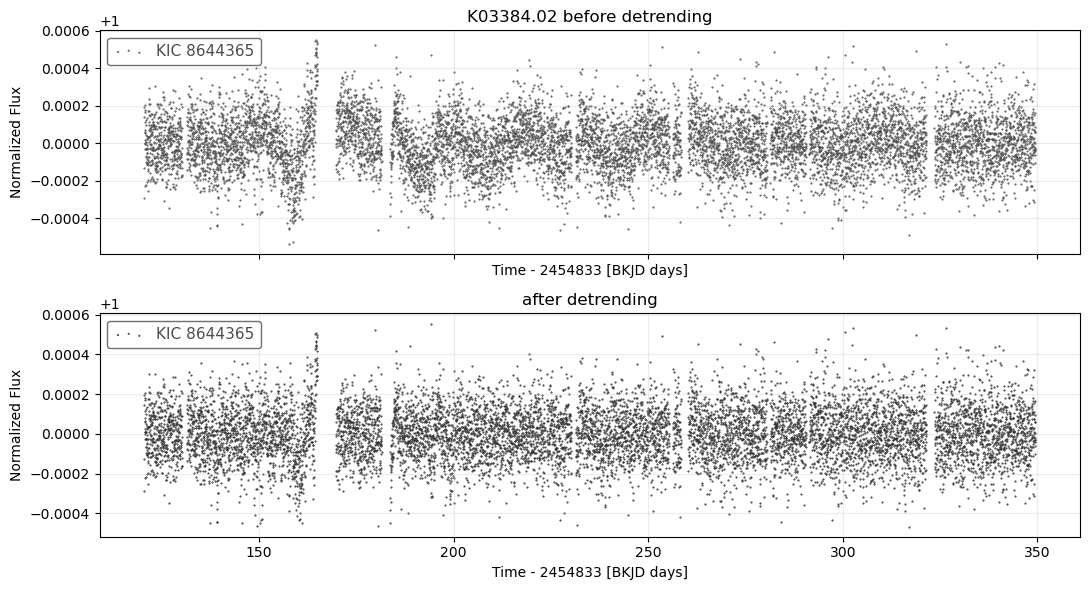

In [8]:
from typing import Optional


def get_lightcurve(kepid: int, max_quarters: int = 8) -> Optional[lk.LightCurve]:
    """Download, join and de-spike one Kepler target. Returns None if nothing is found."""
    target_name = "KIC " + str(kepid)      # lightkurve wants a name like "KIC 10797460"
    search = lk.search_lightcurve(target_name, author="Kepler", cadence="long")
    if len(search) == 0:
        return None

    collection = search[:max_quarters].download_all()
    if collection is None or len(collection) == 0:
        return None

    light_curve = collection.stitch()          # join quarters, scale brightness to about 1
    light_curve = light_curve.remove_nans()
    light_curve = light_curve.remove_outliers(sigma_upper=4, sigma_lower=20)
    return light_curve


def detrend(light_curve: lk.LightCurve, period: float, t0: float,
            duration_days: float) -> lk.LightCurve:
    """Divide out the star's slow brightness changes while protecting the transits."""
    in_transit = light_curve.create_transit_mask(
        period=period,
        transit_time=t0,
        duration=3 * duration_days,            # a generous window, to be safe
    )
    return light_curve.flatten(window_length=401, mask=in_transit)


# --- try it on the first object in the sample ---
first = sample.iloc[0]
raw = get_lightcurve(int(first["kepid"]), max_quarters=4)
flat = detrend(raw, first["koi_period"], first["koi_time0bk"], first["koi_duration"] / 24)

fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
raw.scatter(ax=axes[0], s=1, c="0.3")
axes[0].set_title(first["kepoi_name"] + " before detrending")
flat.scatter(ax=axes[1], s=1, c="C0")
axes[1].set_title("after detrending")
plt.tight_layout()

---
> ### Teacher note
>
> Do this cell together as a class rather than letting students run it alone. Two things are
> worth demonstrating live.
> 
> First, run `flatten()` once **without** the mask and show the result. The transit depth
> shrinks visibly. That single picture explains masking better than any description.
> 
> Second, if anyone asks why `sigma_lower` is set to 20 rather than 4: run it symmetrically
> on a deep eclipsing binary and let them watch the eclipse disappear.

## 2.3 The ten features

The next three cells build the measuring tools. They work on plain NumPy arrays rather
than lightkurve objects, so you can test them on data you invent yourself before trusting
them on a real star.

Everything is measured in three windows around the folded transit:

| Window | Range | Used for |
|---|---|---|
| **core** | `abs(phase) < 0.30 x duration` | the flat bottom of the dip |
| **full** | `abs(phase) < 0.50 x duration` | the whole dip |
| **baseline** | `1.0 x duration < abs(phase) < 4.0 x duration` | the noise level nearby |

**New things in the next cell**

| Name | What it is | What it does |
|---|---|---|
| `phase_fold` | function | Converts absolute time into time since the nearest mid-transit, in days. The transit then sits at 0. |
| `%` | operator | The remainder after division. This is what wraps time around into a repeating cycle. |
| `epoch_number` | function | Works out which numbered transit each point belongs to. This is what lets us separate odd-numbered dips from even-numbered ones. |
| `np.round(...).astype(int)` | method chain | Rounds to the nearest whole number and stores the result as integers. |
| `_depth` | function | Measures how much fainter the in-transit points are than the baseline. The leading underscore is a Python convention meaning 'helper function'. |
| `np.median` | function | The middle value. It is used instead of the mean because a single bad point cannot drag it far. |
| `np.nan` | value | Not a Number. Used to mean 'could not be measured'. |

In [9]:
def phase_fold(time: np.ndarray, period: float, t0: float) -> np.ndarray:
    """Time since the nearest mid-transit, in DAYS, wrapped into [-P/2, +P/2)."""
    return (time - t0 + 0.5 * period) % period - 0.5 * period


def epoch_number(time: np.ndarray, period: float, t0: float) -> np.ndarray:
    """Which numbered transit is each point closest to? Can be negative."""
    return np.round((time - t0) / period).astype(int)


def _depth(flux_in: np.ndarray, flux_out: np.ndarray) -> float:
    """How much light is missing, as a fraction. 0.001 means a 1000 ppm transit."""
    if len(flux_in) < 3 or len(flux_out) < 10:
        return np.nan                      # not enough points to measure anything
    return float(np.median(flux_out) - np.median(flux_in))

**New things in the next cell**

| Name | What it is | What it does |
|---|---|---|
| `measure_features` | function | Returns all ten numbers for one folded light curve, as a dictionary. |
| `dict[str, float]` | type hint | A dictionary whose keys are text and whose values are numbers. This shorthand needs Python 3.9 or later. |
| `core, full, out` | variables (boolean arrays) | True or False for every time step, saying whether that point falls in each window. |
| `flux[core]` | indexing | Selects only the points where the mask is True. |
| `&` | operator on arrays | Combines two masks: True only where both are True. |
| `d_core, d_full` | variables (float) | The depth measured in the core window and in the full window. |
| `np.unique` | function | The list of different values, with duplicates removed. Used to count how many separate transits were seen. |
| `np.sqrt` | function | Square root. |

In [10]:
def measure_features(time: np.ndarray, flux: np.ndarray, period: float,
                     t0: float, duration: float) -> dict:
    """Ten numbers describing one folded transit. `duration` is in DAYS."""
    phase = phase_fold(time, period, t0)
    epoch = epoch_number(time, period, t0)
    features: dict = {}

    core = np.abs(phase) < 0.30 * duration
    full = np.abs(phase) < 0.50 * duration
    out = (np.abs(phase) > 1.00 * duration) & (np.abs(phase) < 4.00 * duration)

    d_core = _depth(flux[core], flux[out])     # depth of the flat bottom
    d_full = _depth(flux[full], flux[out])     # depth averaged over the whole dip

    # --- 1 to 4: the basic measurements -------------------------------
    features["depth_ppm"] = d_core * 1e6
    features["duration_hr"] = duration * 24.0
    features["n_transits"] = len(np.unique(epoch[full]))
    features["scatter_oot_ppm"] = float(np.std(flux[out]) * 1e6) if out.sum() > 10 else np.nan

    # --- 5: signal-to-noise of all the dips stacked together ----------
    features["snr"] = (d_full * 1e6 / features["scatter_oot_ppm"]) * np.sqrt(max(full.sum(), 1))

    # --- 6: is the bottom flat or pointed? U is about 1.05, V is above 1.3
    features["v_shape"] = d_core / d_full if d_full > 0 else np.nan

        # --- 7: odd-even depth difference, measured in units of the noise ---
    #     Two stars orbiting each other give a deep eclipse and then a
    #     shallower one, so if the listed period is twice the real one the
    #     odd-numbered dips differ from the even-numbered ones.
    d_odd = _depth(flux[core & (epoch % 2 == 1)], flux[out])
    d_even = _depth(flux[core & (epoch % 2 == 0)], flux[out])
    noise = np.std(flux[out]) / np.sqrt(max(full.sum() / 2, 1))
    features["odd_even_sigma"] = abs(d_odd - d_even) / noise if noise > 0 else np.nan

    # --- 8: secondary eclipse, half a period after the transit ----------
    #     A planet's night side is far too faint for Kepler to see, so a real
    #     dip here means there is a second star.
    secondary = np.abs(np.abs(phase) - 0.5 * period) < 0.50 * duration
    features["secondary_ppm"] = (_depth(flux[secondary], flux[out]) * 1e6
                                 if secondary.sum() > 3 else 0.0)

    # --- 9: does the depth stay the same from one dip to the next? ------
    per_transit = [_depth(flux[core & (epoch == n)], flux[out])
                   for n in np.unique(epoch[core])]
    per_transit = [d for d in per_transit if np.isfinite(d)]
    features["depth_scatter"] = (float(np.std(per_transit) / np.mean(per_transit))
                                 if len(per_transit) > 2 and np.mean(per_transit) > 0
                                 else np.nan)

    # --- 10: the density the star would need to have --------------------
    #     For a central, circular orbit:  a/R* = P / (pi * T)
    #     and  rho* = 3 * pi * (a/R*)**3 / (G * P**2).
    #     Work in SECONDS. A Sun-like star gives about 1.4 g/cm3. A value
    #     near 0.001 would mean a red giant, which is the signature of a
    #     blended eclipsing binary.
    G = 6.674e-8                                   # cgs units
    period_s = period * 86400.0
    duration_s = duration * 86400.0
    a_over_r = period_s / (np.pi * duration_s)
    features["rho_star_cgs"] = 3.0 * np.pi * a_over_r ** 3 / (G * period_s ** 2)

    return features

### Test your functions on data you built yourself

Before running anything on a real star, invent a planet and an eclipsing binary whose
properties you already know, and check that your functions give back what you put in.

This is how professional astronomers check their code. If you cannot recover a signal you
put in yourself, you cannot trust the answer you get from real data.

**New things in the next cell**

| Name | What it is | What it does |
|---|---|---|
| `fake_lightcurve` | function | Builds an artificial light curve with a transit of known depth and shape, so you can test your measuring functions. |
| `np.random.default_rng` | function | The modern Python 3 way to create a random number generator. Giving it a seed makes the noise repeatable. |
| `rng.normal(0, noise, size)` | method | Random numbers from a bell curve, used here as measurement noise. |
| `np.arange(start, stop, step)` | function | Evenly spaced numbers. Here it creates the observation times, one every 29.4 minutes. |
| `shape="U" or "V"` | argument | Chooses a flat-bottomed dip like a planet, or a pointed dip like a grazing pair of stars. |
| `np.clip(values, low, high)` | function | Forces every value to stay between two limits. |
| `comparison` | variable (DataFrame) | A small table putting the fake planet and the fake binary side by side so you can compare them. |

In [11]:
def fake_lightcurve(period: float, t0: float, duration: float, depth: float,
                    shape: str = "U", secondary: float = 0.0, odd_even: float = 0.0,
                    noise: float = 2e-4, baseline_days: float = 400.0,
                    seed: int = 1) -> tuple[np.ndarray, np.ndarray]:
    """Build an artificial Kepler-like light curve with known properties."""
    rng = np.random.default_rng(seed)
    time = np.arange(0, baseline_days, 29.4 / 60 / 24)      # 29.4-minute steps
    flux = np.ones_like(time) + rng.normal(0, noise, time.size)

    phase = phase_fold(time, period, t0)
    epoch = epoch_number(time, period, t0)
    x = np.abs(phase) / (0.5 * duration)        # 0 at the centre, 1 at the edge

    inside = x < 1
    if shape == "U":
        profile = np.sqrt(np.clip(1 - x ** 4, 0, 1))        # flat bottom, like a planet
    else:
        profile = np.clip(1 - x, 0, 1)                      # pointed, like a grazing pair
    depths = np.where(epoch % 2 == 1, depth + odd_even, depth)
    flux[inside] -= (depths * profile)[inside]

    if secondary > 0:                            # a second dip half a period later
        xs = np.abs(np.abs(phase) - 0.5 * period) / (0.5 * duration)
        flux[xs < 1] -= (secondary * np.clip(1 - xs, 0, 1))[xs < 1]

    return time, flux


PERIOD, T0, DURATION = 8.4, 2.1, 0.13        # days

time_planet, flux_planet = fake_lightcurve(
    PERIOD, T0, DURATION, depth=1200e-6, shape="U", seed=3)
time_binary, flux_binary = fake_lightcurve(
    PERIOD, T0, DURATION, depth=22000e-6, shape="V",
    secondary=3000e-6, odd_even=900e-6, seed=4)

comparison = pd.DataFrame({
    "fake planet": measure_features(time_planet, flux_planet, PERIOD, T0, DURATION),
    "fake binary": measure_features(time_binary, flux_binary, PERIOD, T0, DURATION),
})
comparison.round(2)

,fake planet,fake binary
depth_ppm,1174.47,15733.68
duration_hr,3.12,3.12
n_transits,48.00,48.00
scatter_oot_ppm,194.41,193.96
snr,98.88,1003.69
v_shape,1.07,1.42
odd_even_sigma,1.33,35.85
secondary_ppm,-5.44,1515.56
depth_scatter,0.09,0.02
rho_star_cgs,2.33,2.33


---
> ### Teacher note
>
> Insist on this check before anyone runs the loop over real stars. It costs five minutes and
> saves an entire session of confusion later.
> 
> Expected values from the worked solution: the fake planet gives depth about 1174 ppm,
> `v_shape` 1.07, `secondary_ppm` about -5, `odd_even_sigma` about 1.3. The fake binary gives
> depth about 15700 ppm, `v_shape` 1.42, `secondary_ppm` about 1516, `odd_even_sigma` about 36.
> 
> Note that the measured depth of the binary is lower than the 22000 ppm that was put in.
> That is correct and worth discussing: the depth is measured as a median across a window, and
> a pointed V-shaped dip spends most of its time well above its lowest point. Students who
> spot this discrepancy have understood what the measurement actually does.

## 2.4 Look at what you are measuring

Never trust a number you have not plotted. This function draws the three measurement
windows on top of a folded light curve.

**New things in the next cell**

| Name | What it is | What it does |
|---|---|---|
| `plot_folded` | function | Draws one folded light curve with the three windows shaded. |
| `ax.axvspan(x1, x2, ...)` | method | Shades a vertical band between two x values. |
| `ax.axhline(y, ...)` | method | Draws a horizontal line, used here to mark zero. |
| `alpha` | argument | How see-through a colour is, from 0 to 1. |
| `keep` | variable (boolean array) | Selects only the points near the transit, so the plot is not dominated by empty baseline. |

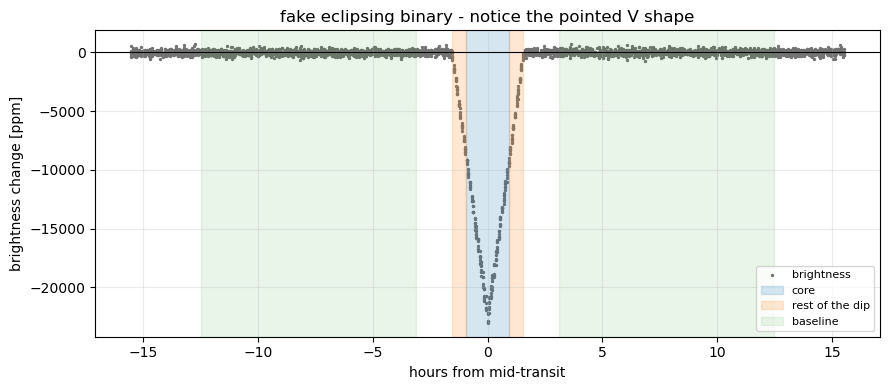

In [12]:
def plot_folded(time: np.ndarray, flux: np.ndarray, period: float, t0: float,
                duration: float, title: str = "") -> None:
    """Draw a folded light curve with the three measurement windows shaded."""
    phase_hours = phase_fold(time, period, t0) * 24
    width = duration * 24
    keep = np.abs(phase_hours) < 5 * width

    fig, ax = plt.subplots(figsize=(9, 4))
    ax.scatter(phase_hours[keep], flux[keep] * 1e6 - 1e6, s=2, c="0.45", label="brightness")

    ax.axvspan(-0.30 * width, 0.30 * width, color="C0", alpha=0.18, label="core")
    ax.axvspan(-0.50 * width, -0.30 * width, color="C1", alpha=0.18)
    ax.axvspan(0.30 * width, 0.50 * width, color="C1", alpha=0.18, label="rest of the dip")
    for side in (-1, 1):
        ax.axvspan(side * 1.0 * width, side * 4.0 * width, color="C2", alpha=0.10,
                   label="baseline" if side == 1 else None)

    ax.axhline(0, color="k", lw=0.8)
    ax.set_xlabel("hours from mid-transit")
    ax.set_ylabel("brightness change [ppm]")
    ax.set_title(title)
    ax.legend(loc="lower right", fontsize=8)
    plt.tight_layout()


plot_folded(time_binary, flux_binary, PERIOD, T0, DURATION,
            "fake eclipsing binary - notice the pointed V shape")

## 2.5 Measure the whole sample

This is the slow cell. Expect roughly 20 to 40 minutes for a hundred targets on a home
connection. It saves its progress after every ten objects, so if it stops you can simply
run it again and it will carry on from where it left off.

**New things in the next cell**

| Name | What it is | What it does |
|---|---|---|
| `FEATURE_FILE` | variable (Path) | Where the finished table of measurements is saved. |
| `.exists()` | method | True if the file is already there, so we can continue rather than start again. |
| `.to_dict("records")` | method | Turns a DataFrame into a list of dictionaries, one per row, which is easy to add to. |
| `already_done` | variable (set) | The objects measured on a previous run, so they can be skipped. |
| `.iterrows()` | method | Steps through a DataFrame one row at a time. |
| `try / except` | statement | Runs the risky code, and if it fails, prints a message and carries on with the next object instead of stopping everything. |
| `np.isfinite` | function | False for missing or infinite values. Used to keep only usable points. |
| `light_curve.time.value` | attribute chain | The plain array of numbers behind a lightkurve time column. |

In [14]:
FEATURE_FILE = DATA_DIR / "measured_features.csv"

if FEATURE_FILE.exists():
    finished = pd.read_csv(FEATURE_FILE)
else:
    finished = pd.DataFrame(columns=["kepoi_name"])

rows = finished.to_dict("records")
already_done = set(finished["kepoi_name"])

for position, row in sample.iterrows():
    if row["kepoi_name"] in already_done:
        continue                              # measured on an earlier run

    try:
        light_curve = get_lightcurve(int(row["kepid"]), max_quarters=8)
        if light_curve is None:
            print(row["kepoi_name"], "- no data available")
            continue

        duration_days = row["koi_duration"] / 24.0
        light_curve = detrend(light_curve, row["koi_period"],
                              row["koi_time0bk"], duration_days)

        time = np.asarray(light_curve.time.value, dtype=float)
        flux = np.asarray(light_curve.flux.value, dtype=float)
        good = np.isfinite(time) & np.isfinite(flux)

        features = measure_features(time[good], flux[good], row["koi_period"],
                                    row["koi_time0bk"], duration_days)
        features.update(kepoi_name=row["kepoi_name"],
                        kepid=int(row["kepid"]),
                        is_fp=int(row["is_fp"]))
        rows.append(features)

        print(position + 1, "of", len(sample), " ", row["kepoi_name"],
              " depth =", round(features["depth_ppm"]), "ppm",
              " v_shape =", round(features["v_shape"], 2))

    except Exception as error:
        print(row["kepoi_name"], "- FAILED -", type(error).__name__, "-", error)

    if len(rows) % 10 == 0:                   # save progress every ten objects
        pd.DataFrame(rows).to_csv(FEATURE_FILE, index=False)

pd.DataFrame(rows).to_csv(FEATURE_FILE, index=False)
print()
print("saved", len(rows), "rows to", FEATURE_FILE)

K06634.01 - FAILED - ValueError - cannot reshape array of size 0 into shape (0,newaxis)
K06696.01 - FAILED - ValueError - cannot reshape array of size 0 into shape (0,newaxis)

saved 98 rows to koi_project\measured_features.csv


---
> ### Teacher note
>
> Set this running as homework between sessions. If the school network blocks MAST, or
> bandwidth is limited, distribute your own `measured_features.csv` so that Parts 3 and 4 can
> go ahead for everyone.
> 
> Expect five to fifteen failures out of a hundred. That is normal, and reporting the failures
> honestly is part of the assessment rather than a sign of a broken pipeline.

### Stage B deliverable &mdash; teacher copy

The file `measured_features.csv` with at least 80 objects measured; four folded plots with
the windows drawn on and one sentence under each saying what gives that object away; and a
count of how many targets failed to download and why.

---
# PART 3 &mdash; Stage C: Training the model

From here on, every number going into the model is one you measured yourself from the
brightness data. No catalogue columns are used.

**New things in the next cell**

| Name | What it is | What it does |
|---|---|---|
| `MY_FEATURES` | variable (list of str) | The ten columns you measured. This is now the complete input to the model. |
| `.replace([np.inf, -np.inf], np.nan)` | method | Turns infinities into missing values so they can be removed in one step. |
| `.describe()` | method | A quick summary of each column: count, mean, minimum, maximum and quartiles. |
| `.T` | attribute | Transpose: swaps rows and columns, which makes the summary easier to read. |

In [15]:
from sklearn.model_selection import GroupKFold, cross_val_predict
from sklearn.metrics import (precision_recall_curve, average_precision_score,
                             ConfusionMatrixDisplay)

features_table = pd.read_csv(FEATURE_FILE)

MY_FEATURES = [
    "depth_ppm", "duration_hr", "n_transits", "scatter_oot_ppm", "snr",
    "v_shape", "odd_even_sigma", "secondary_ppm", "depth_scatter", "rho_star_cgs",
]

features_table = (features_table
                  .replace([np.inf, -np.inf], np.nan)
                  .dropna(subset=MY_FEATURES + ["is_fp"]))

percent_fake = 100 * features_table["is_fp"].mean()
print(len(features_table), "objects usable")
print("of those,", round(percent_fake, 1), "percent are false positives")
features_table[MY_FEATURES].describe().T.round(2)

79 objects usable
of those, 41.8 percent are false positives


,count,mean,std,min,25%,50%,75%,max
depth_ppm,79.0,21177.66,59971.81,27.39,160.54,434.27,4353.95,374099.61
duration_hr,79.0,5.54,4.04,1.86,2.89,4.28,6.83,25.01
n_transits,79.0,130.15,196.99,3.00,22.50,42.00,162.00,1081.00
scatter_oot_ppm,79.0,4617.03,20890.10,44.73,211.83,404.94,1109.51,178487.78
snr,79.0,173.12,453.29,2.72,10.12,17.17,70.30,2715.97
v_shape,79.0,1.23,0.21,0.79,1.10,1.17,1.36,2.02
odd_even_sigma,79.0,12.10,48.36,0.03,0.71,1.91,3.65,324.12
secondary_ppm,79.0,7992.28,47914.81,-950.26,-11.32,6.67,30.68,409817.87
depth_scatter,79.0,1.12,2.62,0.02,0.22,0.51,1.15,22.48
rho_star_cgs,79.0,2.45,3.90,0.01,0.53,1.03,2.56,19.41


## 3.1 Split by star, train, and read the report

Look at the **recall for the false positive class** first. That is the fraction of the
fakes your model caught, and it is the number this whole project is about.

**New things in the next cell**

| Name | What it is | What it does |
|---|---|---|
| `X, y, groups` | variables | The inputs, the answers, and the star each row belongs to. |
| `ConfusionMatrixDisplay.from_predictions` | class method | Draws the confusion matrix as a coloured grid instead of printing it as numbers. |
| `proba` | variable (array) | The probability the model gives each object of being a false positive, between 0 and 1. |
| `predict_proba(...)[:, 1]` | method and indexing | Takes the probability of the second class, which here is 'false positive'. |
| `(proba > 0.5).astype(int)` | expression | Turns probabilities into yes-or-no answers by comparing with a threshold. |

                precision    recall  f1-score   support

        planet      0.923     0.857     0.889        14
false positive      0.833     0.909     0.870        11

      accuracy                          0.880        25
     macro avg      0.878     0.883     0.879        25
  weighted avg      0.884     0.880     0.880        25



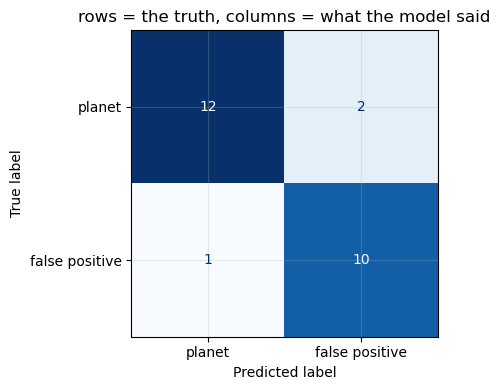

In [16]:
X = features_table[MY_FEATURES]
y = features_table["is_fp"]
groups = features_table["kepid"]

splitter = GroupShuffleSplit(n_splits=1, test_size=0.30, random_state=RANDOM_STATE)
train_idx, test_idx = next(splitter.split(X, y, groups=groups))

shared = set(groups.iloc[train_idx]) & set(groups.iloc[test_idx])
assert not shared, "some stars appear on both sides of the split"

forest = RandomForestClassifier(
    n_estimators=500,
    min_samples_leaf=2,
    class_weight="balanced",
    random_state=RANDOM_STATE,
    n_jobs=-1,
)
forest.fit(X.iloc[train_idx], y.iloc[train_idx])

proba = forest.predict_proba(X.iloc[test_idx])[:, 1]
predictions = (proba > 0.5).astype(int)

print(classification_report(y.iloc[test_idx], predictions,
                            target_names=["planet", "false positive"], digits=3))

ConfusionMatrixDisplay.from_predictions(
    y.iloc[test_idx], predictions,
    display_labels=["planet", "false positive"],
    colorbar=False, cmap="Blues",
)
plt.title("rows = the truth, columns = what the model said")
plt.tight_layout()

## 3.2 Precision and recall, compared with guessing

When the two classes are unequal in size, a precision-recall curve is far more informative
than the ROC curve you may have seen elsewhere. The dashed line shows what you would get by
guessing.

**New things in the next cell**

| Name | What it is | What it does |
|---|---|---|
| `precision_recall_curve` | function | Returns precision and recall at every possible threshold, so the trade-off can be drawn as a curve. |
| `average_precision_score` | function | A single number summarising the whole curve. Higher is better, and the guessing baseline is the fraction of false positives. |
| `plt.axhline(..., ls="--")` | method | A dashed horizontal line, used for the guessing baseline. |

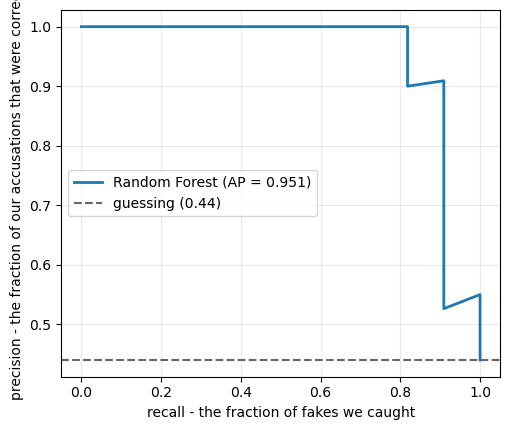

In [17]:
precision, recall, _ = precision_recall_curve(y.iloc[test_idx], proba)
average_precision = average_precision_score(y.iloc[test_idx], proba)
guessing = y.iloc[test_idx].mean()

plt.figure(figsize=(5.2, 4.4))
model_label = "Random Forest (AP = " + str(round(average_precision, 3)) + ")"
guess_label = "guessing (" + str(round(guessing, 2)) + ")"

plt.plot(recall, precision, lw=2, label=model_label)
plt.axhline(guessing, ls="--", c="0.4", label=guess_label)
plt.xlabel("recall - the fraction of fakes we caught")
plt.ylabel("precision - the fraction of our accusations that were correct")
plt.legend()
plt.tight_layout()

A single 30% test split depends on which objects happened to land in it. Cross-validation
repeats the whole train-and-test cycle five times, using a different fifth of the data as
the test set each time, so every object is tested exactly once. The score it gives is more
trustworthy.

**New things in the next cell**

| Name | What it is | What it does |
|---|---|---|
| `GroupKFold` | class (scikit-learn) | Splits the data into five parts while keeping each star whole, so no star is ever split across two parts. |
| `cross_val_predict` | function | Runs training and testing five times and collects all the predictions together. |
| `method="predict_proba"` | argument | Asks for probabilities rather than yes-or-no answers, so the average precision can be calculated. |
| `cv_proba` | variable (array) | One probability per object, each produced by a model that had never seen that object during training. |

In [18]:
# A 5-fold grouped cross-validation is a fairer score than one single split,
# because every object is used for testing exactly once.
cv_proba = cross_val_predict(
    forest, X, y, groups=groups, cv=GroupKFold(n_splits=5),
    method="predict_proba", n_jobs=-1,
)[:, 1]

cv_average_precision = average_precision_score(y, cv_proba)

print("cross-validated average precision:", round(cv_average_precision, 3))
print("guessing baseline                :", round(y.mean(), 3))

cross-validated average precision: 0.936
guessing baseline                : 0.418


## 3.3 Which measurement is doing the work?

**New things in the next cell**

| Name | What it is | What it does |
|---|---|---|
| `feature_importances_` | attribute | How much each of your ten features contributed. The ten values add up to 1. |
| `.sort_values()` | method | Puts the importances in order so the bar chart reads clearly. |
| `.plot.barh` | method | A horizontal bar chart, which suits long feature names. |

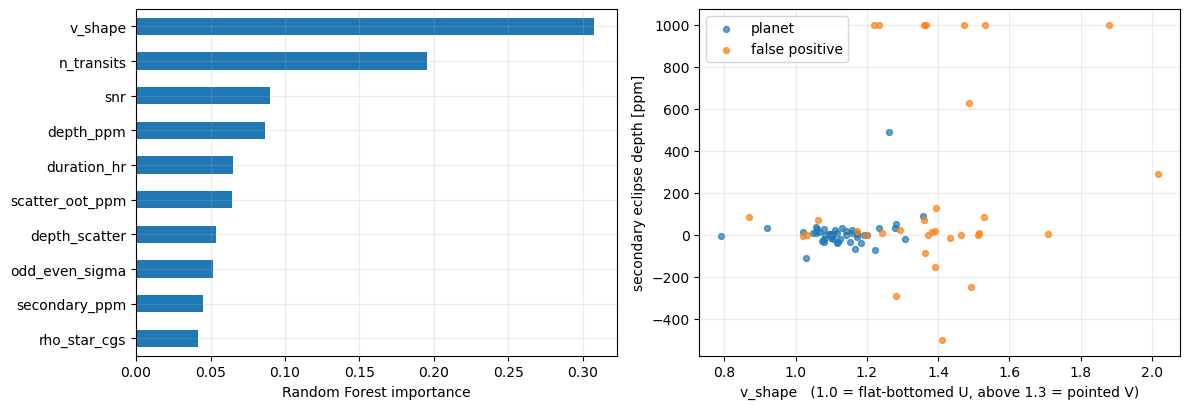

In [22]:
importances = pd.Series(forest.feature_importances_, index=MY_FEATURES).sort_values()

fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
importances.plot.barh(ax=ax[0], color="C0")
ax[0].set_xlabel("Random Forest importance")

for label, subset in features_table.groupby("is_fp"):
    ax[1].scatter(subset["v_shape"], subset["secondary_ppm"].clip(-500, 1000),
                  s=18, alpha=0.7,
                  label="false positive" if label == 1 else "planet")
ax[1].set_xlabel("v_shape   (1.0 = flat-bottomed U, above 1.3 = pointed V)")
ax[1].set_ylabel("secondary eclipse depth [ppm]")
ax[1].legend()

plt.tight_layout()

---
> ### Teacher note
>
> The scatter plot is where students most often over-claim. The two clouds overlap
> substantially, and a group that writes "the classes separate clearly" has not looked
> carefully. Ask them to estimate what fraction of points sit in the overlap region, and to
> say what that fraction implies for the best recall any model could reach on these two
> features alone.

### Stage C deliverable &mdash; teacher copy

The classification report, the confusion matrix and the precision-recall curve, all from
the student's own measured features; plus two or three sentences on whether they beat the
Stage A result and whether the most important features are the ones the physics predicts.

---
# PART 4 &mdash; Stage D: Finding the limit

Your model now gets some objects wrong. In this Part you show that one part of that error
could not have been avoided with the data you have.

Kepler records four flags saying **why** each object was rejected:

| Flag | What it means |
|---|---|
| `koi_fpflag_nt` | Not transit-like. The shape is wrong. |
| `koi_fpflag_ss` | Stellar eclipse. There is a secondary eclipse, or the shape is clearly a pair of stars. |
| `koi_fpflag_co` | **Centroid offset.** The light was lost from the wrong place on the camera. |
| `koi_fpflag_ec` | Ephemeris match. The same period and timing as a known variable star nearby. |

The first two describe the **shape** of the light curve, so your features have a fair chance
of catching them. But a centroid offset is measured from the **camera pixels**, by asking
where the missing light was. A light curve is a single brightness value at each moment and
has thrown that information away. So has your model.

**New things in the next cell**

| Name | What it is | What it does |
|---|---|---|
| `flags` | variable (list of str) | The four false-positive flag columns. Used for analysis only, never for training. |
| `.merge(..., on=..., how="left")` | method | Joins two tables side by side, matching rows by a shared column. |
| `caught / missed` | variables (DataFrame) | The true false positives the model found, and the ones it did not. |
| `.mean()` | method on 0/1 columns | The mean of a column of ones and zeros is the fraction of rows that are 1, which is exactly what we want here. |
| `.plot.bar(...)` | method | A vertical bar chart comparing the two groups. |

false positives in the test set : 11
  caught by the model           : 10
  missed by the model           : 1

There are too few missed objects here to draw a conclusion.
Either increase N_PER_CLASS, or use the cross-validated predictions
instead of this single 30% test split.
fraction of objects carrying each flag:
                  caught  missed
not transit-like     0.1     1.0
stellar eclipse      0.8     0.0
centroid offset      0.2     0.0
ephemeris match      0.1     0.0


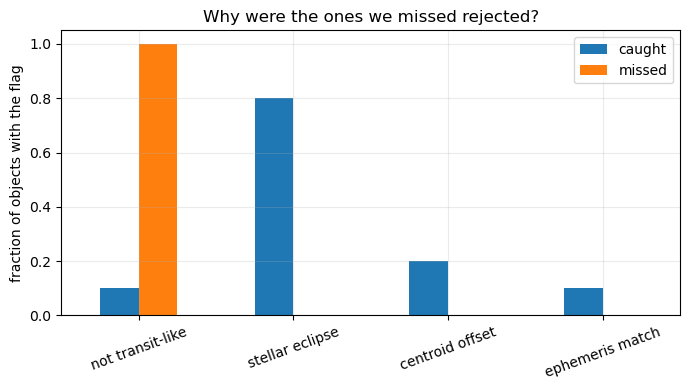

In [20]:
flags = ["koi_fpflag_nt", "koi_fpflag_ss", "koi_fpflag_co", "koi_fpflag_ec"]

# Attach the flags for ANALYSIS ONLY. They must never be used for training.
test_set = (features_table.iloc[test_idx]
            .merge(koi[["kepoi_name"] + flags], on="kepoi_name", how="left"))
test_set["prediction"] = predictions

true_fakes = test_set[test_set["is_fp"] == 1]
caught = true_fakes[true_fakes["prediction"] == 1]
missed = true_fakes[true_fakes["prediction"] == 0]

print("false positives in the test set :", len(true_fakes))
print("  caught by the model           :", len(caught))
print("  missed by the model           :", len(missed))
print()

if len(missed) < 3:
    print("There are too few missed objects here to draw a conclusion.\n"
          "Either increase N_PER_CLASS, or use the cross-validated predictions\n"
          "instead of this single 30% test split.")

summary = pd.DataFrame({
    "caught": caught[flags].mean(),
    "missed": missed[flags].mean(),
}).round(2)
summary.index = ["not transit-like", "stellar eclipse", "centroid offset", "ephemeris match"]

print("fraction of objects carrying each flag:")
print(summary.to_string())

summary.plot.bar(figsize=(7, 4), rot=20)
plt.ylabel("fraction of objects with the flag")
plt.title("Why were the ones we missed rejected?")
plt.tight_layout()

## 4.1 Writing your conclusion

Your conclusion should be a number with an uncertainty and a reason, not a description.
Use this shape:

> Using ten features measured directly from Kepler light curves, a Random Forest identified
> **XX% ± Y%** of false positives at a precision of **ZZ%** (grouped 5-fold
> cross-validation, N = ___ objects). Of the false positives the model missed, **AA%**
> carried the centroid-offset flag, compared with **BB%** of those it caught. A centroid
> offset is measured from the camera pixels rather than from the light curve, so this type
> of false positive cannot be identified from brightness measurements alone. The errors
> that remain were mostly low signal-to-noise objects, with a median SNR of ___.

Then say clearly what would improve the result: more objects, camera pixel data, or a
neural network trained on the folded curve instead of on ten hand-made numbers.

---
> ### Teacher note
>
> Mark the conclusion on its structure, not on the size of the recall. The four things to
> look for are a number, an uncertainty, a comparison against the guessing baseline, and a
> physical reason for the errors that remain.
> 
> A group reporting 0.62 recall with a correct grouped split and an honest error analysis has
> done better work than a group reporting 0.98 with a leaked column, and the marks should say
> so clearly.

### Stage D deliverable &mdash; teacher copy

The bar chart comparing the four flags between caught and missed objects, and a written
conclusion in the form given above.

## 4.2 If you finish early

- **Add artificial transits.** Insert transits of known depth into real light curves that
  have already been detrended. The labels are then completely reliable and you can make as
  many as you like, which is what a neural network needs. Measure the depth at which your
  model stops finding them.
- **Use the camera pixels.** Download the target pixel files and calculate your own centroid
  shift. Adding that one feature should let you catch some of the false positives you could
  not catch before.
- **Change the model.** Run a Support Vector Machine and k-Nearest Neighbours on the same
  table of features. If the Random Forest is only slightly better, that tells you the
  features matter more than the choice of algorithm.
- **Work without labels.** Run an Isolation Forest on the feature table and look at the
  twenty most unusual objects. Decide for each one whether it is a planet, a false positive,
  or something else.